In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('/content/customer_churn_cleaned (5).csv')

df.head()
print("Shape:", df.shape)


Shape: (1100, 30)


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Customer_ID              1100 non-null   object
 1   Customer_Name            1100 non-null   object
 2   Gender                   1060 non-null   object
 3   Age                      1053 non-null   object
 4   City                     978 non-null    object
 5   State                    1012 non-null   object
 6   Signup_Date              1079 non-null   object
 7   Last_Login               820 non-null    object
 8   Tenure                   1068 non-null   object
 9   Contract_Type            1085 non-null   object
 10  Subscription_Plan        1074 non-null   object
 11  Monthly_Charges          1064 non-null   object
 12  Total_Charges            1054 non-null   object
 13  Payment_Method           1075 non-null   object
 14  Auto_Payment             1065 non-null  

In [50]:
df.head()

,Customer_ID,Customer_Name,Gender,Age,City,State,Signup_Date,Last_Login,Tenure,Contract_Type,...,Discount,Satisfaction_Score,Customer_Service_Rating,Device_Type,Referral_Source,Churn,Churn_Date,Churn_Reason,Customer_Notes,Data_Source
0,cus_0249,ananya rao,M,38 years,warangal,telangana,Jul 11 2026,08/27/2026,1 months,M2M,...,Customer receives 25% discount,2 out of 5,Poor,Mobile,friend referral,Active,NaN,Not churned,NaN,CRM
1,cus_0106,Riya Kapoor,Male,49,Tirupati,Andhra Pradesh,Aug 26 2024,08/22/2026,24,Two-Year,...,No Discount,Average,4 stars,android phone,Friend,0,NaN,Not churned,customer happy with service,mobile app
2,cus_0197,SURESH BABU,F,26,NaN,Delhi,21-07-2026,27-08-2026,1,Monthly,...,0.1,5,Excellent,Android Phone,Google,0,NaN,NaN,moved to competitor,Mobile App
3,CUS-0891,Sneha Patel,Female,55,delhi,Not Available,16-Apr-26,30-Aug-26,1 years,Monthly,...,5%,Very Satisfied,Not Available,iPhone,Google,N,NaN,NaN,NaN,API
4,CUS-0333,amit shah,M,39,Not Available,Telangana,Jul 14 2026,08/27/2026,1 years,Monthly,...,15%,3 out of 5,2,Android,Google,No,NaN,NaN,customer happy with service,Import


In [51]:
df['Churn'].unique()

array(['Active', '0', 'N', 'No', 'Churned', '1', 'Y', 'Yes'], dtype=object)

In [52]:
df['Churn'] = df['Churn'].astype("string").replace({'Active': 'Not Churn', '0': 'Churn', 'N': 'Not Churn', 'No': 'Not Churn', 'Churned': 'Churn', '1': 'Churn', 'Y': 'Churn', 'Yes': 'Churn'})

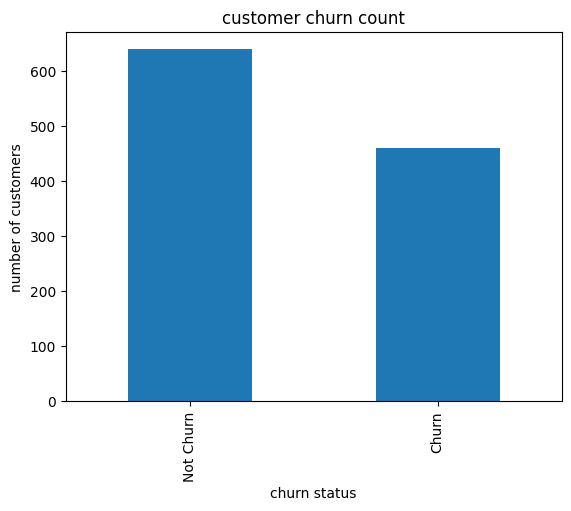

In [53]:
df['Churn'].value_counts().plot(kind='bar')
plt.title('customer churn count')
plt.xlabel('churn status')
plt.ylabel('number of customers')
plt.show()

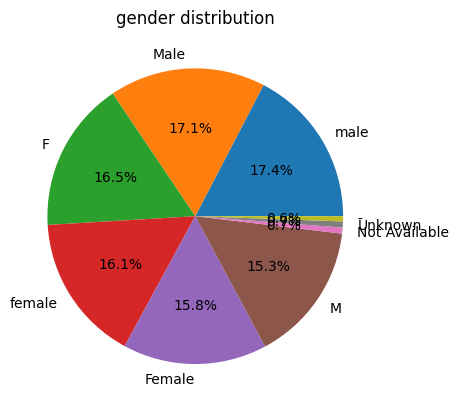

In [54]:
df['Gender'].value_counts().plot(kind='pie',autopct='%1.1f%%')

plt.title('gender distribution')
plt.ylabel('')
plt.show()

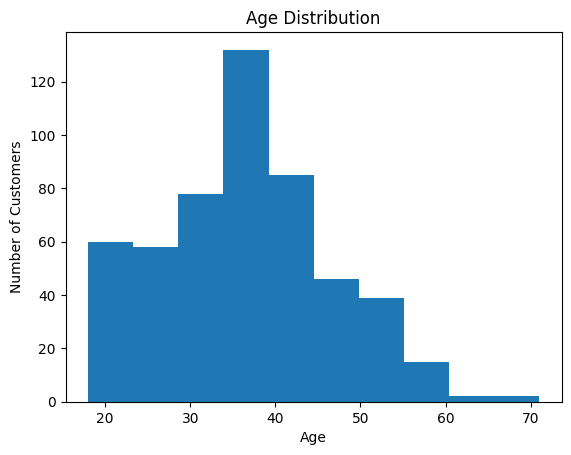

In [55]:
df['Age']=pd.to_numeric(df['Age'],errors='coerce')
df['Age'].dropna().plot(kind='hist',bins=10)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

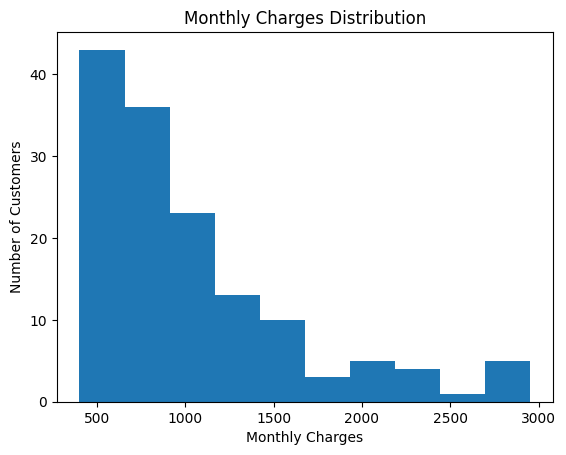

In [56]:
df['Monthly_Charges'] = pd.to_numeric(df['Monthly_Charges'], errors='coerce')
df['Monthly_Charges'].dropna().plot(kind='hist', bins=10)

plt.title('Monthly Charges Distribution')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')
plt.show()

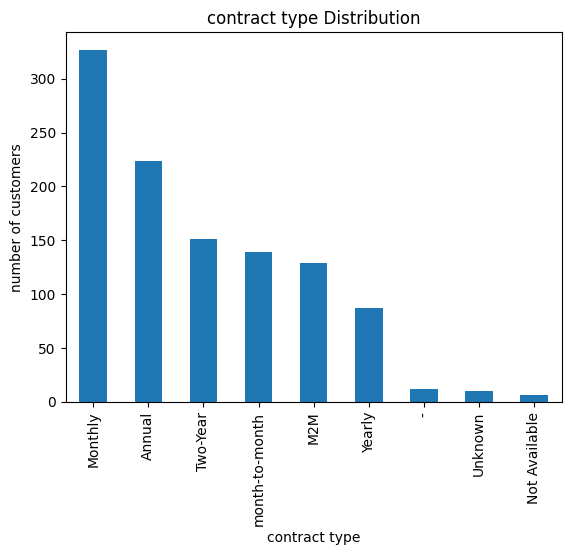

In [57]:
df['Contract_Type'].value_counts().plot(kind='bar')

plt.title('contract type Distribution')
plt.xlabel('contract type')
plt.ylabel('number of customers')
plt.show()

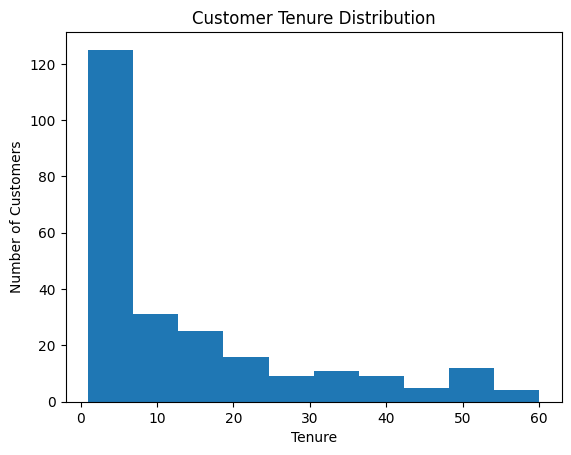

In [58]:
df['Tenure'] = pd.to_numeric(df['Tenure'], errors='coerce')
df['Tenure'].dropna().plot(kind='hist', bins=10)
plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure')
plt.ylabel('Number of Customers')
plt.show()

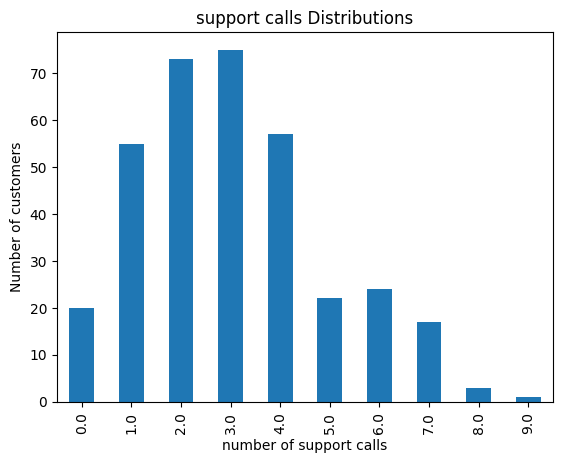

In [59]:
df['Support_Calls']=pd.to_numeric(df['Support_Calls'],errors='coerce')
df['Support_Calls'].dropna().value_counts().sort_index().plot(kind='bar')

plt.title('support calls Distributions')
plt.xlabel('number of support calls')
plt.ylabel('Number of customers')
plt.show()

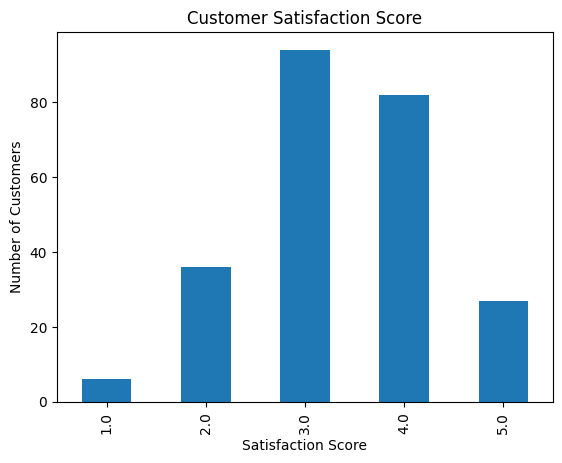

In [60]:
df['Satisfaction_Score'] = pd.to_numeric(df['Satisfaction_Score'], errors='coerce')

df['Satisfaction_Score'].dropna().value_counts().sort_index().plot(kind='bar')

plt.title('Customer Satisfaction Score')
plt.xlabel('Satisfaction Score')
plt.ylabel('Number of Customers')
plt.show()

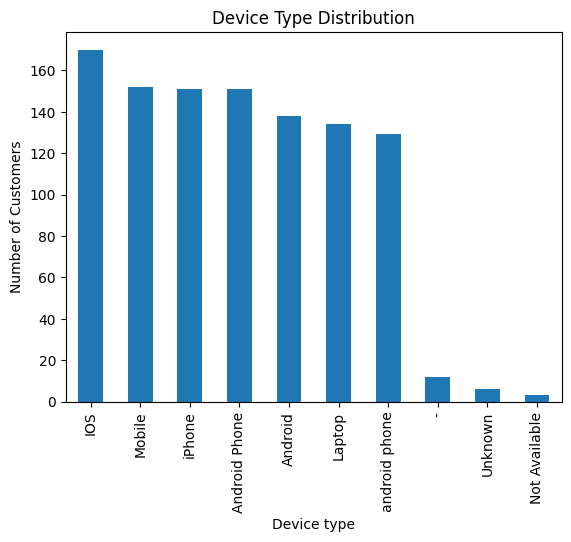

In [61]:
df['Device_Type'].value_counts().plot(kind='bar')
plt.title('Device Type Distribution')
plt.xlabel('Device type')
plt.ylabel('Number of Customers')
plt.show()

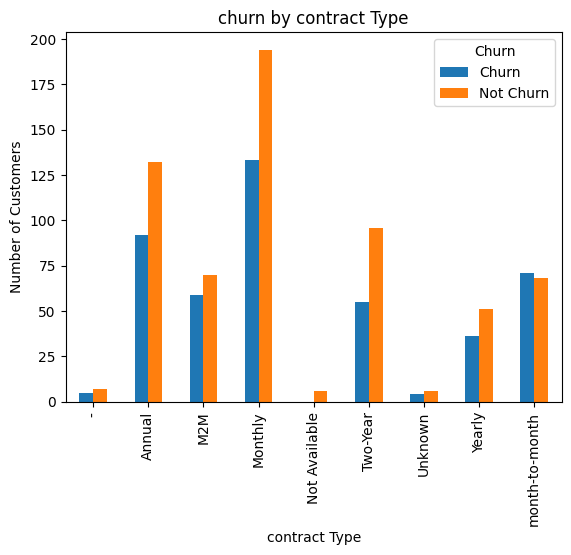

In [62]:
pd.crosstab(df['Contract_Type'],df['Churn']).plot(kind='bar')

plt.title('churn by contract Type')
plt.xlabel('contract Type')
plt.ylabel('Number of Customers')
plt.show()

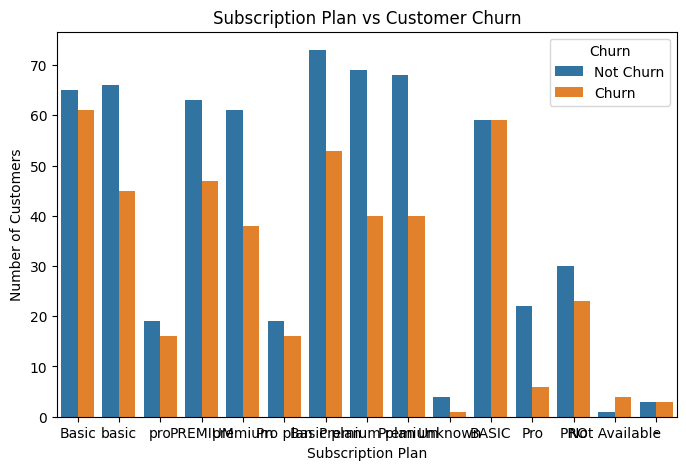

In [63]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Subscription_Plan",
    hue="Churn"
)

plt.title("Subscription Plan vs Customer Churn")
plt.xlabel("Subscription Plan")
plt.ylabel("Number of Customers")
plt.show()

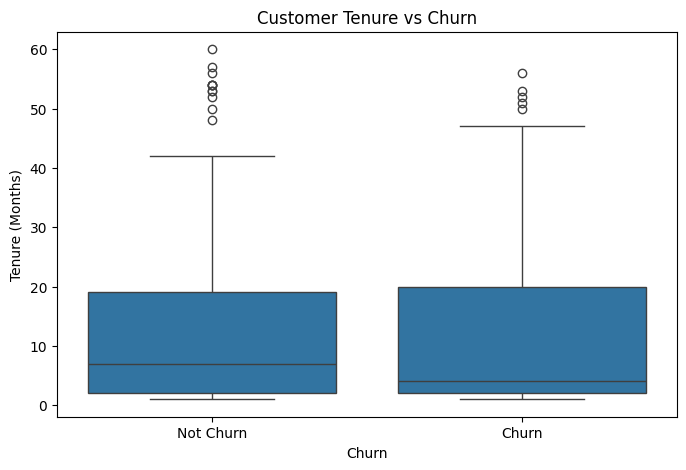

In [64]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="Tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

heatmap,scatterplot,linegraphs,vilon plot

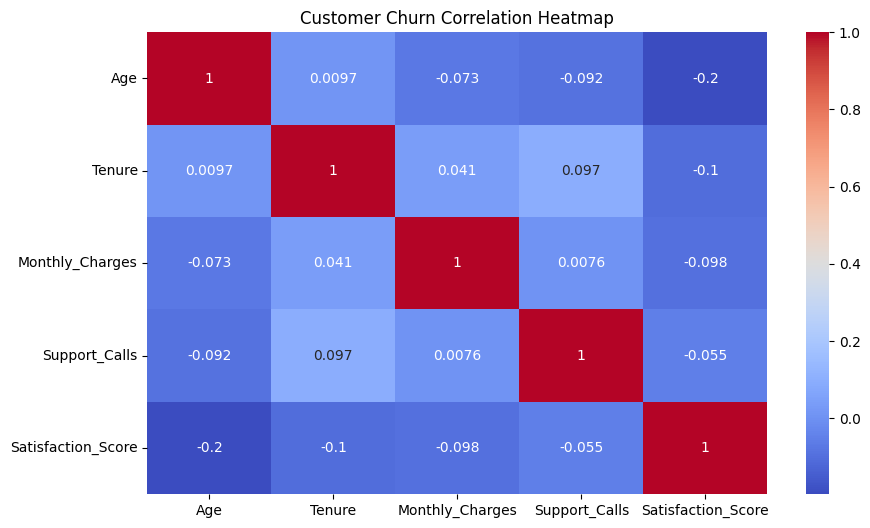

In [65]:
num_df = df.select_dtypes(include="number")
plt.figure(figsize=(10, 6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm")

plt.title("Customer Churn Correlation Heatmap")
plt.show()

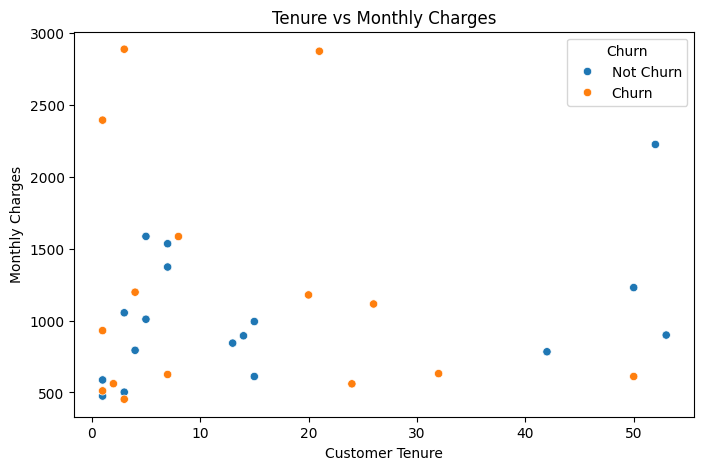

In [66]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Tenure",
    y="Monthly_Charges",
    hue="Churn"
)

plt.title("Tenure vs Monthly Charges")
plt.xlabel("Customer Tenure")
plt.ylabel("Monthly Charges")

plt.show()

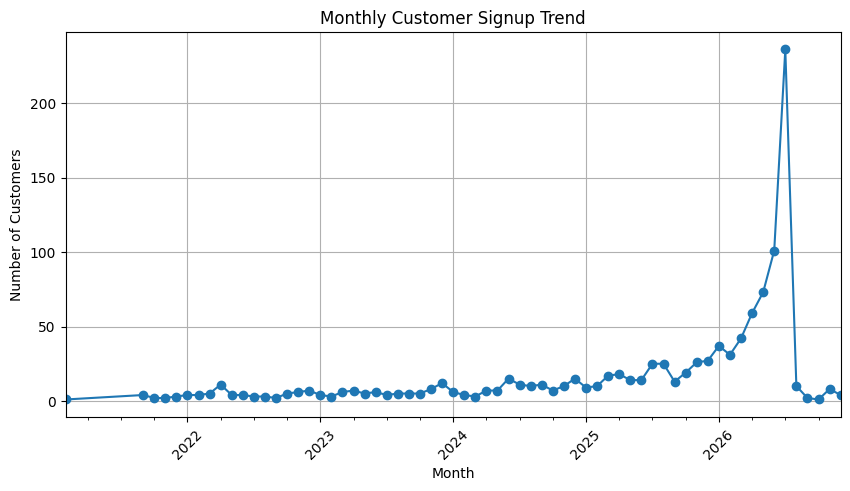

In [67]:
df["Signup_Date"] = pd.to_datetime(df["Signup_Date"], format='mixed', dayfirst=True, errors='coerce')

monthly_data = (
    df.groupby(df["Signup_Date"].dt.to_period("M"))
      .size()
)

plt.figure(figsize=(10, 5))

monthly_data.plot(kind="line", marker="o")

plt.title("Monthly Customer Signup Trend")
plt.xlabel("Month")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

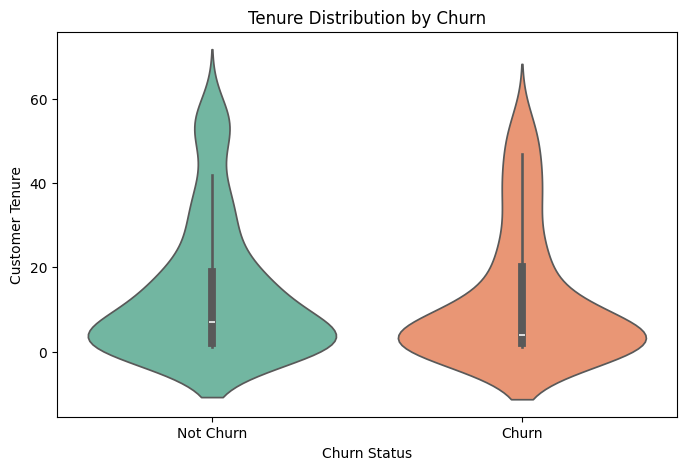

In [68]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="Churn",
    y="Tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn Status")
plt.ylabel("Customer Tenure")

plt.show()